# Interacción con la atmósfera y con la superficie

Entre la fuente y el sensor la radiación interactúa dos veces con la atmósfera y una vez con la superficie. Cada interacción altera la señal, y entenderlas es la base tanto para elegir las bandas de un sensor como para interpretar o corregir una imagen {cite}`chuvieco2008,lillesand2015`.

## Atenuación

La intensidad de la radiación disminuye por dos razones. La atenuación geométrica se debe a que la energía se reparte sobre una superficie cada vez mayor a medida que se aleja de la fuente, de modo que la intensidad decrece con el cuadrado de la distancia. La atenuación atmosférica se debe a la absorción y la dispersión por gases y partículas, y sigue la ley de Beer-Lambert: la intensidad decrece exponencialmente con el espesor óptico $\tau$ del medio atravesado,

$$I = I_0 \, e^{-\tau / \cos\theta},$$

donde $\theta$ es el ángulo cenital de la trayectoria. Cuanto más inclinado está el Sol, más larga es la trayectoria y mayor la atenuación, lo que explica parte de la diferencia entre imágenes tomadas en distintas épocas del año.

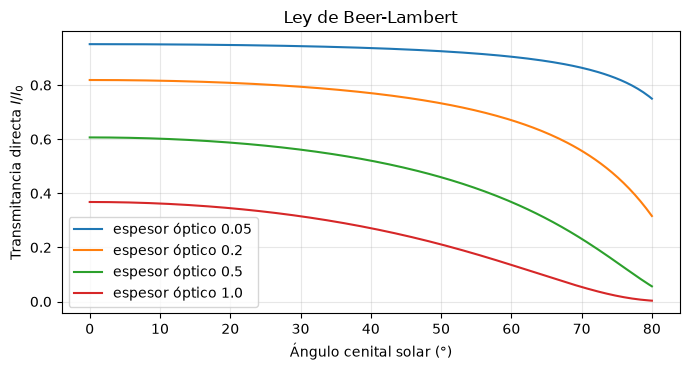

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

theta = np.radians(np.linspace(0, 80, 200))
fig, ax = plt.subplots(figsize=(7, 3.8))
for tau in [0.05, 0.2, 0.5, 1.0]:
    ax.plot(np.degrees(theta), np.exp(-tau / np.cos(theta)), label=f'espesor óptico {tau}')
ax.set_xlabel('Ángulo cenital solar (°)'); ax.set_ylabel('Transmitancia directa $I/I_0$')
ax.set_title('Ley de Beer-Lambert'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Absorción y ventanas atmosféricas

Los gases de la atmósfera absorben la radiación en bandas específicas. El ozono absorbe el ultravioleta, el vapor de agua y el dióxido de carbono absorben amplias regiones del infrarrojo, y el oxígeno tiene bandas estrechas en el rojo lejano. Las regiones donde la atmósfera es casi transparente se llaman ventanas atmosféricas, y en ellas se ubican las bandas de los sensores: el visible y el infrarrojo cercano, varias ventanas en el infrarrojo de onda corta (alrededor de 1.6 y 2.2 µm), la ventana térmica entre 8 y 14 µm y las microondas, que atraviesan casi sin pérdida las nubes. La figura siguiente es un esquema simplificado de la transmitancia de la atmósfera con las bandas de Landsat 8 superpuestas.

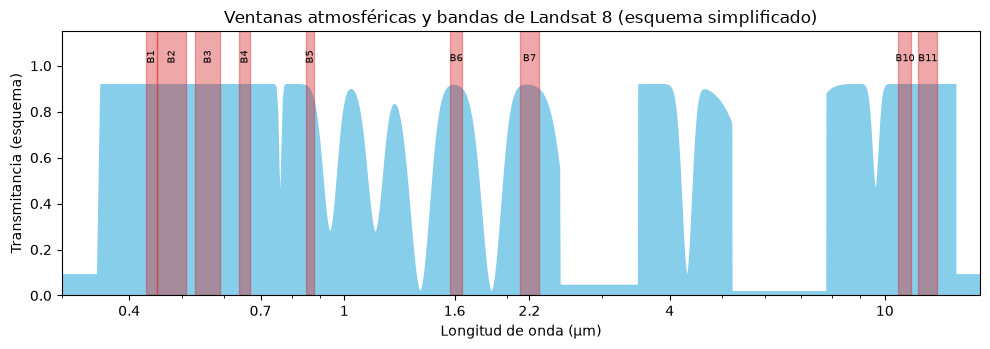

In [2]:
lam = np.linspace(0.3, 15, 3000)
def absorcion(centro, ancho, prof):
    return prof * np.exp(-0.5 * ((lam - centro) / ancho)**2)
T = np.ones_like(lam)
T -= np.where(lam < 0.35, 1.0, 0) * 0.9                         # ozono (UV)
for cen, an, pr in [(0.76, 0.005, 0.6), (0.94, 0.03, 0.7), (1.14, 0.04, 0.7), (1.38, 0.06, 0.98),
                    (1.87, 0.08, 0.98), (2.7, 0.15, 1.0), (4.3, 0.1, 0.9), (6.3, 0.6, 1.0), (9.6, 0.15, 0.5)]:
    T -= absorcion(cen, an, pr)
T[(lam > 2.5) & (lam < 3.5)] = 0.05
T[(lam > 5.2) & (lam < 7.8)] = 0.02
T[lam > 13.5] = 0.1
T = np.clip(T * 0.92, 0, 1)
bandas_l8 = {'B1': (0.43, 0.45), 'B2': (0.45, 0.51), 'B3': (0.53, 0.59), 'B4': (0.64, 0.67), 'B5': (0.85, 0.88),
             'B6': (1.57, 1.65), 'B7': (2.11, 2.29), 'B10': (10.6, 11.19), 'B11': (11.5, 12.51)}
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(lam, T, color='skyblue')
for b, (a, z) in bandas_l8.items():
    ax.axvspan(a, z, color='tab:red', alpha=0.4)
    ax.text((a + z) / 2, 1.02, b, ha='center', fontsize=7, rotation=90 if z < 1 else 0)
ax.set_xscale('log'); ax.set_xlim(0.3, 15); ax.set_ylim(0, 1.15)
ax.set_xticks([0.4, 0.7, 1, 1.6, 2.2, 4, 10]); ax.set_xticklabels(['0.4', '0.7', '1', '1.6', '2.2', '4', '10'])
ax.set_xlabel('Longitud de onda (µm)'); ax.set_ylabel('Transmitancia (esquema)')
ax.set_title('Ventanas atmosféricas y bandas de Landsat 8 (esquema simplificado)')
plt.tight_layout(); plt.show()

## Dispersión

La dispersión redirige la radiación sin absorberla. Su tipo depende de la relación entre el tamaño de las partículas y la longitud de onda. La dispersión de Rayleigh la producen moléculas mucho más pequeñas que la longitud de onda; su intensidad es proporcional a $\lambda^{-4}$, de modo que el azul se dispersa unas cinco veces más que el rojo, lo que explica el color del cielo y el velo azulado de las imágenes de la banda azul. La dispersión de Mie la producen partículas de tamaño comparable a la longitud de onda, como el humo, el polvo o los aerosoles, y depende menos de ella. La dispersión no selectiva la producen gotas y cristales mucho mayores que la longitud de onda, afecta por igual a todo el visible y por eso las nubes y la niebla se ven blancas {cite}`ccrs`.

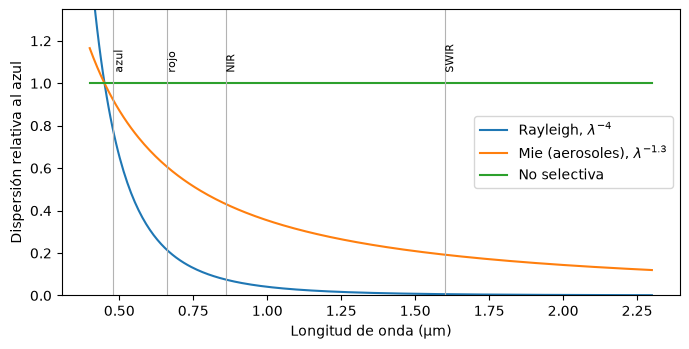

Rayleigh: el azul (0.45 µm) se dispersa 4.4 veces más que el rojo (0.65 µm)


In [3]:
lam_v = np.linspace(0.4, 2.3, 300)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(lam_v, (0.45 / lam_v)**4, label=r'Rayleigh, $\lambda^{-4}$')
ax.plot(lam_v, (0.45 / lam_v)**1.3, label=r'Mie (aerosoles), $\lambda^{-1.3}$')
ax.plot(lam_v, np.ones_like(lam_v), label='No selectiva')
for b, l0 in [('azul', 0.48), ('rojo', 0.66), ('NIR', 0.86), ('SWIR', 1.6)]:
    ax.axvline(l0, color='0.7', lw=0.8); ax.text(l0, 1.05, b, rotation=90, fontsize=8, va='bottom')
ax.set_xlabel('Longitud de onda (µm)'); ax.set_ylabel('Dispersión relativa al azul')
ax.legend(); ax.set_ylim(0, 1.35); plt.tight_layout(); plt.show()
print(f'Rayleigh: el azul (0.45 µm) se dispersa {(0.65/0.45)**4:.1f} veces más que el rojo (0.65 µm)')

## Interacción con la superficie

La radiación que llega a la superficie se refleja, se absorbe o se transmite. La proporción de cada una depende de la longitud de onda y del material, y esa dependencia es lo que permite distinguir coberturas en una imagen. La forma de la reflexión depende de la rugosidad comparada con la longitud de onda: una superficie lisa, como el agua en calma, produce reflexión especular, en una sola dirección, mientras que una superficie rugosa produce reflexión difusa o lambertiana, igual en todas las direcciones. Casi todas las superficies naturales están entre estos dos extremos.

## Firmas espectrales

La curva de reflectancia en función de la longitud de onda se llama firma espectral, y cada material tiene una forma característica {cite}`lillesand2015,chuvieco2008`.

La vegetación sana absorbe el azul y el rojo para la fotosíntesis, por la clorofila, refleja algo más el verde y presenta un salto brusco de reflectancia en el borde rojo, cerca de 0.7 µm, porque la estructura interna de las hojas dispersa con fuerza el infrarrojo cercano. En el infrarrojo de onda corta la reflectancia baja de nuevo por la absorción del agua de las hojas, con mínimos a 1.45 y 1.95 µm. Una planta estresada pierde el contraste entre el rojo y el infrarrojo cercano, y en ese contraste se basa el NDVI.

El agua clara refleja poco en el visible, sobre todo en el azul y el verde, y casi nada en el infrarrojo, donde la absorbe por completo; por eso los cuerpos de agua se ven negros en las bandas infrarrojas. Los sedimentos en suspensión aumentan su reflectancia en el visible.

Los suelos y las rocas tienen curvas más suaves que aumentan con la longitud de onda. Su forma depende de la humedad, que baja la reflectancia en todo el espectro; de la materia orgánica, que la baja sobre todo en el visible; de los óxidos de hierro, que producen absorciones cerca de 0.9 µm y un aumento fuerte hacia el rojo; y de los minerales arcillosos y carbonatos, que producen absorciones características en el infrarrojo de onda corta, cerca de 2.2 y 2.33 µm. Estas absorciones son las que aprovecha la cartografía de alteraciones hidrotermales en exploración minera.

La celda siguiente construye firmas espectrales simplificadas y simula cómo las vería Sentinel-2, promediando cada curva dentro de sus bandas.

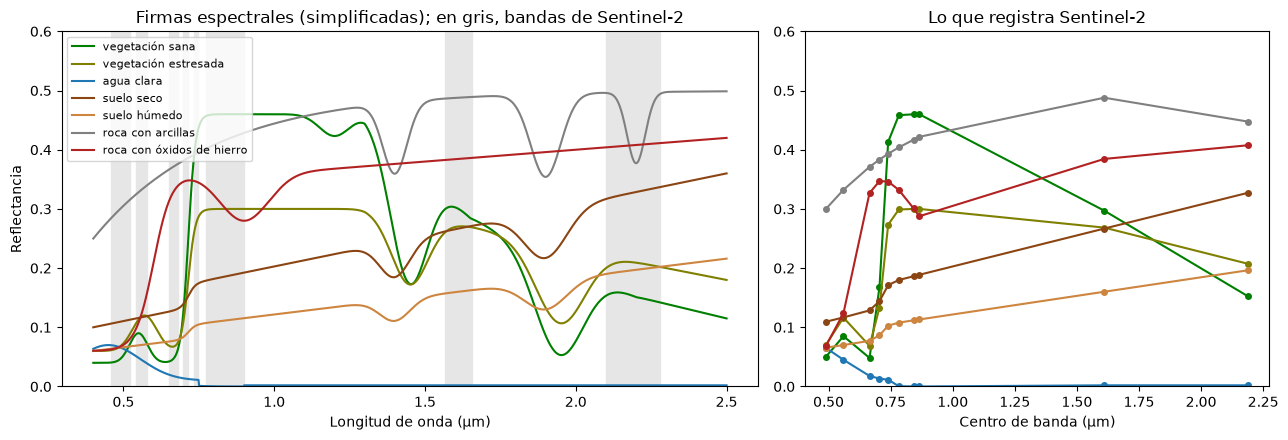

In [4]:
lam = np.linspace(0.4, 2.5, 1000)
g = lambda c, w: np.exp(-0.5 * ((lam - c) / w)**2)
borde = 1 / (1 + np.exp(-(lam - 0.715) / 0.012))
caida_swir = np.interp(lam, [0.4, 1.3, 1.65, 2.2, 2.5], [1, 1, 0.62, 0.33, 0.25])
veg = (0.04 + 0.05 * g(0.55, 0.03) + 0.42 * borde) * caida_swir
veg *= 1 - 0.08 * g(1.2, 0.05) - 0.55 * g(1.45, 0.06) - 0.75 * g(1.95, 0.08)
veg_estres = (0.06 + 0.06 * g(0.57, 0.04) + 0.24 * borde) * np.interp(lam, [0.4, 1.3, 1.65, 2.2, 2.5], [1, 1, 0.9, 0.7, 0.6])
veg_estres *= 1 - 0.4 * g(1.45, 0.06) - 0.55 * g(1.95, 0.08)
agua = 0.06 * np.exp(-((lam - 0.45) / 0.15)**2) + 0.01 * (lam < 0.75)
agua = np.where(lam > 0.9, 0.002, agua)
suelo = 0.10 + 0.22 * (lam - 0.4) / 2.1 + 0.04 * borde - 0.06 * g(1.4, 0.05) - 0.08 * g(1.9, 0.07)
suelo_hum = 0.6 * suelo
arcilla = 0.25 + 0.25 * (1 - np.exp(-(lam - 0.4) / 0.4)) - 0.12 * g(1.4, 0.04) - 0.14 * g(1.9, 0.05) - 0.12 * g(2.2, 0.03)
oxido = 0.06 + 0.30 / (1 + np.exp(-(lam - 0.6) / 0.03)) - 0.08 * g(0.9, 0.08) + 0.04 * (lam - 1) * (lam > 1)
firmas = {'vegetación sana': (veg, 'green'), 'vegetación estresada': (veg_estres, 'olive'),
          'agua clara': (agua, 'tab:blue'), 'suelo seco': (suelo, 'saddlebrown'),
          'suelo húmedo': (suelo_hum, 'peru'), 'roca con arcillas': (arcilla, 'gray'),
          'roca con óxidos de hierro': (oxido, 'firebrick')}

s2 = {'B2': (0.49, 0.065), 'B3': (0.56, 0.035), 'B4': (0.665, 0.03), 'B5': (0.705, 0.015),
      'B6': (0.74, 0.015), 'B7': (0.783, 0.02), 'B8': (0.842, 0.115), 'B8A': (0.865, 0.02),
      'B11': (1.61, 0.09), 'B12': (2.19, 0.18)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [3, 2]})
for n, (f, col) in firmas.items():
    ax[0].plot(lam, f, color=col, label=n)
    cent = [s2[b][0] for b in s2]
    val = [f[(lam >= c0 - w / 2) & (lam <= c0 + w / 2)].mean() for c0, w in s2.values()]
    ax[1].plot(cent, val, 'o-', color=col, ms=4)
for c0, w in s2.values():
    ax[0].axvspan(c0 - w / 2, c0 + w / 2, color='0.9', zorder=0)
ax[0].set_xlabel('Longitud de onda (µm)'); ax[0].set_ylabel('Reflectancia')
ax[0].set_title('Firmas espectrales (simplificadas); en gris, bandas de Sentinel-2')
ax[0].legend(fontsize=8)
ax[1].set_xlabel('Centro de banda (µm)'); ax[1].set_title('Lo que registra Sentinel-2')
for a in ax: a.set_ylim(0, 0.6)
plt.tight_layout(); plt.show()

La segunda gráfica muestra que, al pasar de una curva continua a diez bandas, se pierden detalles finos como la absorción de las arcillas en 2.2 µm, que queda dentro de la banda ancha B12. Un sensor hiperespectral, con cientos de bandas estrechas, sí la resolvería. Este compromiso entre el número de bandas y su ancho es la resolución espectral, que se trata en el capítulo {doc}`05_Resolucion`.

## Para profundizar

El capítulo 2 de {cite}`chuvieco2008` y el capítulo 1 de {cite}`lillesand2015` presentan las firmas espectrales de los principales materiales. Las bibliotecas espectrales del USGS y de ECOSTRESS (antes ASTER) contienen miles de espectros medidos en laboratorio de minerales, rocas, suelos y vegetación, y son el punto de partida para cualquier trabajo de cartografía litológica.